# Pertemuan 3 — Preprocessing Data 2
### Praktik: feature engineering dan menyiapkan data untuk model

<a href="https://colab.research.google.com/github/[username]/[nama-repo]/blob/main/pertemuan-03/03_Preprocessing_Data_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Ganti `[username]` dan `[nama-repo]` pada tautan di atas (dan pada `URL_DATA` di bagian 2) dengan alamat repositori GitHub kelas.

**Setelah menyelesaikan notebook ini, kamu bisa:**

1. Menilai apakah data yang sudah bersih **siap dipakai model**.
2. Membuat fitur baru yang bermakna bagi bisnis (*feature engineering*).
3. Mengubah kategori menjadi angka dengan ordinal encoding dan one-hot encoding.
4. Menyetarakan skala dengan standardisasi dan min-max scaling.
5. Membagi data latih dan data uji, serta mengenali *data leakage*.
6. Menyatukan semua langkah dalam sebuah *pipeline* yang bisa dipakai ulang.

**Dataset:** Customer Personality Analysis, sama seperti Pertemuan 2. Penjelasan kolomnya ada di `README.md`.

**Perkiraan waktu:** 60–70 menit.

---
## 1. Business case: data siap model

Masih di **Juli 2014**, di tim marketing *RetailKu* (perusahaan fiktif). Laporan profil pelanggan yang sudah kamu bersihkan diterima direksi. Direksi menyetujui **kampanye ke-7**, dengan satu syarat: kampanye harus lebih tepat sasaran daripada sebelumnya, karena setiap penawaran yang dikirim ada biayanya.

Tim data science akan membantu dengan dua hal:

- **Pertemuan 4:** mengelompokkan pelanggan menjadi beberapa segmen.
- **Pertemuan 5:** memprediksi pelanggan mana yang kemungkinan besar merespons kampanye (kolom `Response`).

Data scientist senior mengirim pesan kepadamu:

> *"Data bersihnya sudah bagus. Tapi model belum bisa langsung memakainya. Tolong kirimkan **tabel siap model**: satu baris per pelanggan, semua kolom berupa angka, skalanya setara, dan pastikan **tidak ada informasi yang bocor**. Satu lagi: buat prosesnya bisa diulang untuk data pelanggan baru."*

| Pertanyaan bisnis | Pertanyaan data / teknik |
|---|---|
| Apa saja yang menggambarkan seorang pelanggan? | Fitur baru apa yang bisa dibuat dari kolom yang ada? |
| Bagaimana model membaca "PhD" atau "Married"? | Bagaimana mengubah kategori menjadi angka? |
| Apakah pendapatan (puluhan ribu) dan jumlah anak (0–3) bisa dibandingkan begitu saja? | Bagaimana menyetarakan skala? |
| Bagaimana memastikan model diuji dengan adil? | Bagaimana membagi data dan mencegah kebocoran? |
| Bagaimana jika besok ada pelanggan baru? | Bagaimana membuat semua langkah bisa diulang? |

---
## 2. Menyiapkan alat dan data

In [1]:
import os
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

WARNA = "#2B6F7E"
WARNA_SOROT = "#B4501F"

In [2]:
# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Tentukan path tempat Anda menyimpan file di Google Drive
FILE_DATA = '/content/drive/MyDrive/UNIPA 2026/Meet 3/marketing_campaign_bersih.csv'

bersih = pd.read_csv(FILE_DATA)

Mounted at /content/drive


---
## 3. Eksplorasi: bisakah data ini langsung dipakai model?

Sebagian besar model machine learning hanya mengerti **angka**, dan menganggap angka yang lebih besar sebagai "lebih penting" atau "lebih jauh". Dengan sudut pandang itu, jelajahi data bersih berikut dan catat apa saja yang belum siap.

In [3]:
bersih.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0


In [4]:
bersih.dtypes.value_counts()

,count
int64,23
object,3
float64,1


In [6]:
bersih.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2026 entries, 0 to 2025
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2026 non-null   int64  
 1   Year_Birth           2026 non-null   int64  
 2   Education            2026 non-null   object 
 3   Marital_Status       2026 non-null   object 
 4   Income               2026 non-null   float64
 5   Kidhome              2026 non-null   int64  
 6   Teenhome             2026 non-null   int64  
 7   Dt_Customer          2026 non-null   object 
 8   Recency              2026 non-null   int64  
 9   MntWines             2026 non-null   int64  
 10  MntFruits            2026 non-null   int64  
 11  MntMeatProducts      2026 non-null   int64  
 12  MntFishProducts      2026 non-null   int64  
 13  MntSweetProducts     2026 non-null   int64  
 14  MntGoldProds         2026 non-null   int64  
 15  NumDealsPurchases    2026 non-null   i

In [8]:
# mengubah tipe data Dt_Customer
bersih["Dt_Customer"] = pd.to_datetime(bersih["Dt_Customer"])
bersih.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2026 entries, 0 to 2025
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2026 non-null   int64         
 1   Year_Birth           2026 non-null   int64         
 2   Education            2026 non-null   object        
 3   Marital_Status       2026 non-null   object        
 4   Income               2026 non-null   float64       
 5   Kidhome              2026 non-null   int64         
 6   Teenhome             2026 non-null   int64         
 7   Dt_Customer          2026 non-null   datetime64[ns]
 8   Recency              2026 non-null   int64         
 9   MntWines             2026 non-null   int64         
 10  MntFruits            2026 non-null   int64         
 11  MntMeatProducts      2026 non-null   int64         
 12  MntFishProducts      2026 non-null   int64         
 13  MntSweetProducts     2026 non-nul

In [10]:
kolom_bukan_angka = [k for k in bersih.columns if not pd.api.types.is_numeric_dtype(bersih[k])]
print("Kolom bukan angka:", kolom_bukan_angka)

Kolom bukan angka: ['Education', 'Marital_Status', 'Dt_Customer']


💬 **Amati 1:** kolom mana yang bukan angka? Bisakah model menghitung dengan "PhD" atau dengan sebuah tanggal?

In [9]:
bersih.describe().T[["min", "max"]]

,min,max
ID,0.0,11191.0
Year_Birth,1940.0,1996.0
Income,1730.0,162397.0
Kidhome,0.0,2.0
Teenhome,0.0,2.0
Dt_Customer,2012-07-30 00:00:00,2014-06-29 00:00:00
Recency,0.0,99.0
MntWines,0.0,1493.0
MntFruits,0.0,199.0
MntMeatProducts,0.0,1725.0


💬 **Amati 2:** bandingkan rentang (`min` sampai `max`) antar kolom. Jika sebuah model menghitung "jarak" antar pelanggan, kolom mana yang akan paling mendominasi hanya karena angkanya besar?

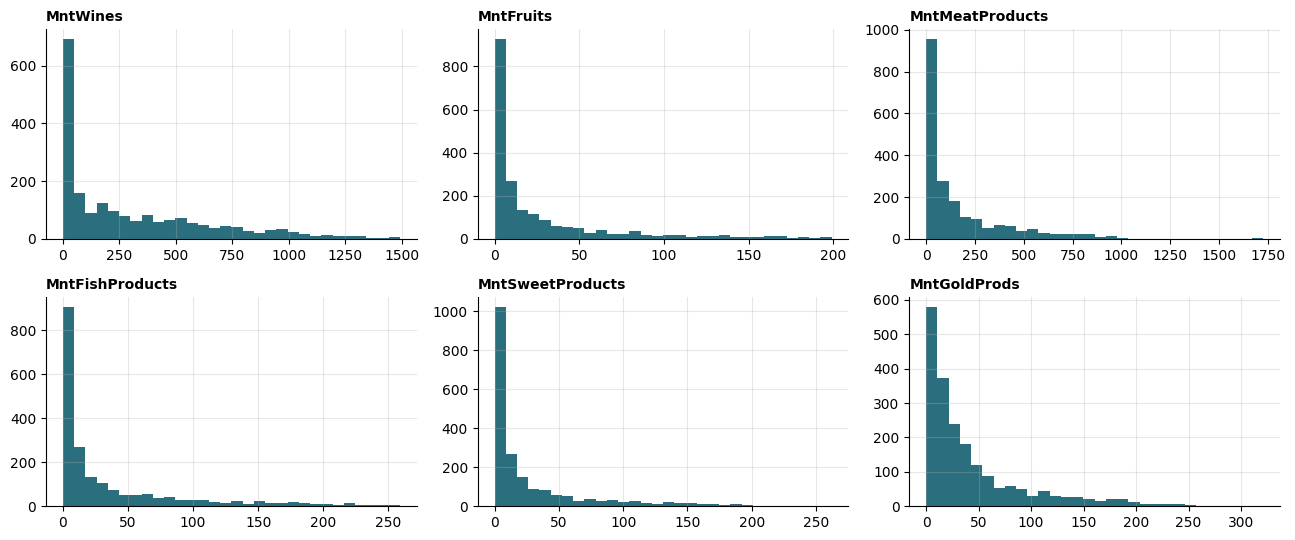

In [11]:
kolom_belanja = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for ax, kolom in zip(axes.ravel(), kolom_belanja):
    ax.hist(bersih[kolom], bins=30, color=WARNA)
    ax.set_title(kolom, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

💬 **Amati 3:** seperti apa bentuk sebaran kolom belanja? Simetris, atau menumpuk di kiri dengan ekor panjang ke kanan?

💬 **Amati 4:** informasi tentang satu hal kadang tersebar di beberapa kolom. Misalnya belanja tersebar di 6 kolom, anak di 2 kolom (`Kidhome`, `Teenhome`), dan pembelian di 3 kanal. Informasi apa yang mungkin berguna bagi tim marketing tetapi belum ada sebagai kolom sendiri?

### Catatan kesiapan data

| No | Masalah untuk model | Kolom | Ide solusi |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |

<details>
<summary><b>Bandingkan dengan catatanmu</b> (klik setelah berdiskusi)</summary>

| Masalah | Solusi | Bagian |
|---|---|---|
| Informasi tersebar atau tersembunyi (tanggal, tahun lahir, banyak kolom belanja) | Membuat fitur baru | 4 |
| Kolom teks (`Education`, `Marital_Status`) | Encoding | 5 |
| Skala antar kolom sangat berbeda | Scaling | 6 |
| Sebaran sangat miring | Transformasi log | 4.5 |
| Masih ada nilai kosong | Diisi di dalam pipeline | 7–8 |

</details>

---
## 4. Feature engineering: membuat fitur baru

**Fitur** adalah kolom yang dipakai model untuk belajar. *Feature engineering* berarti meracik kolom-kolom yang ada menjadi fitur yang lebih bermakna, terutama bagi orang bisnis.

Kita bekerja pada salinan bernama `df`.

In [12]:
df = bersih.copy()

### 4.1 Dari tanggal dan tahun menjadi angka yang bermakna

Model tidak bisa memakai tanggal secara langsung, dan tahun lahir `1970` kurang bermakna dibanding **umur**.

In [14]:
TAHUN_ACUAN = 2014
TANGGAL_ACUAN = pd.Timestamp("2014-07-01")   # "hari ini" dalam cerita

In [15]:
df["Age"] = TAHUN_ACUAN - df["Year_Birth"]
df["Tenure_days"] = (TANGGAL_ACUAN - df["Dt_Customer"]).dt.days   # lama menjadi pelanggan (hari)

df[["Year_Birth", "Age", "Dt_Customer", "Tenure_days"]].head()

,Year_Birth,Age,Dt_Customer,Tenure_days
0,1957,57,2012-09-04,665
1,1954,60,2014-03-08,115
2,1965,49,2013-08-21,314
3,1984,30,2014-02-10,141
4,1981,33,2014-01-19,163


### 4.2 Agregasi: menggabungkan beberapa kolom

In [16]:
kolom_pembelian = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
kolom_kampanye_lalu = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]

df["Children"] = df["Kidhome"] + df["Teenhome"]
df["TotalSpend"] = df[kolom_belanja].sum(axis=1)
df["TotalPurchases"] = df[kolom_pembelian].sum(axis=1)
df["TotalAcceptedPrev"] = df[kolom_kampanye_lalu].sum(axis=1)   # kampanye 1-5 yang pernah diterima

df[["Children", "TotalSpend", "TotalPurchases", "TotalAcceptedPrev"]].describe().round(1)

,Children,TotalSpend,TotalPurchases,TotalAcceptedPrev
count,2026.0,2026.0,2026.0,2026.0
mean,1.0,607.5,12.6,0.3
std,0.7,603.4,7.2,0.7
min,0.0,5.0,0.0,0.0
25%,0.0,69.0,6.0,0.0
50%,1.0,396.5,12.0,0.0
75%,1.0,1047.8,18.0,0.0
max,3.0,2525.0,32.0,4.0


💬 **Diskusi:** mengapa `TotalAcceptedPrev` **tidak** ikut menjumlahkan kolom `Response`? Simpan jawabanmu; kita bahas di bagian 7.

### 4.3 Rasio: belanja rata-rata per transaksi

Rasio sering lebih informatif daripada angka mentah. Pelanggan yang belanja 1.000 dalam 5 transaksi berbeda dengan yang belanja 1.000 dalam 50 transaksi.

In [17]:
print("Pelanggan dengan TotalPurchases = 0:", (df["TotalPurchases"] == 0).sum())

Pelanggan dengan TotalPurchases = 0: 6


💬 **Amati:** apa yang terjadi jika kita membagi dengan nol? Dan apakah masuk akal ada pelanggan yang punya belanja, tetapi jumlah pembeliannya nol?

Kita ganti pembagi nol dengan `NaN` (kosong) agar tidak muncul nilai tak hingga. Nilai kosong itu nanti diisi di dalam pipeline.

In [18]:
df["AvgSpendPerPurchase"] = df["TotalSpend"] / df["TotalPurchases"].replace(0, np.nan)

df[["TotalSpend", "TotalPurchases", "AvgSpendPerPurchase"]].head()

,TotalSpend,TotalPurchases,AvgSpendPerPurchase
0,1617,22,73.500000
1,27,4,6.750000
2,776,20,38.800000
3,53,6,8.833333
4,422,14,30.142857


### 4.4 Binning: mengelompokkan angka menjadi rentang

Kadang orang bisnis lebih mudah berpikir dalam kelompok, misalnya "pelanggan usia 31–45" daripada "pelanggan usia 37".

In [19]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 30, 45, 60, 120],
                        labels=["<=30", "31-45", "46-60", ">60"])
df["IncomeGroup"] = pd.qcut(df["Income"], q=4,
                            labels=["Q1 rendah", "Q2", "Q3", "Q4 tinggi"])

df["AgeGroup"].value_counts().sort_index()

,count
AgeGroup,
<=30,234
31-45,886
46-60,664
>60,242


`pd.cut` memakai batas yang kita tentukan sendiri. `pd.qcut` membagi data menjadi kelompok yang **jumlah anggotanya hampir sama** (di sini 4 kuartil).

Kelompok seperti ini enak untuk insight. Contoh: berapa persen pelanggan di tiap kelompok pendapatan yang merespons kampanye terakhir?

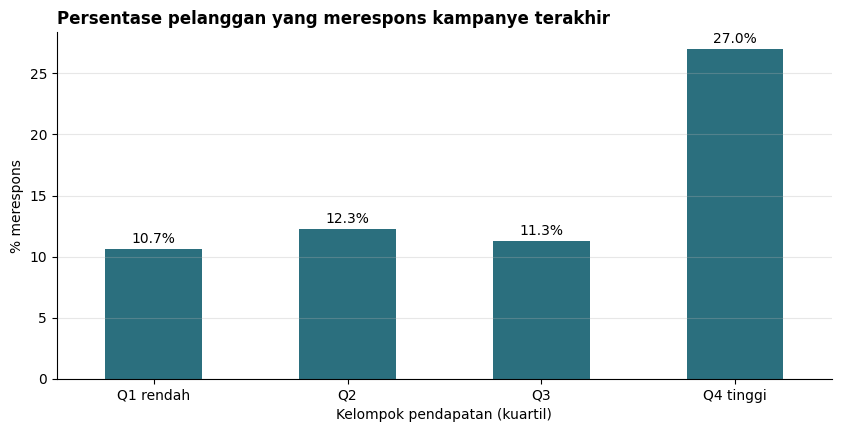

In [20]:
respons_per_kelompok = df.groupby("IncomeGroup", observed=True)["Response"].mean() * 100

ax = respons_per_kelompok.plot(kind="bar", color=WARNA, rot=0)
ax.set_title("Persentase pelanggan yang merespons kampanye terakhir", loc="left", fontweight="bold")
ax.set_xlabel("Kelompok pendapatan (kuartil)")
ax.set_ylabel("% merespons")
ax.grid(axis="x", visible=False)
for i, nilai in enumerate(respons_per_kelompok):
    ax.text(i, nilai + 0.5, f"{nilai:.1f}%", ha="center")
plt.show()

💬 **Diskusi:** apa yang bisa disimpulkan tim marketing dari grafik ini? Ingat, ini baru hubungan (korelasi), belum tentu sebab-akibat.

### 4.5 Transformasi log untuk sebaran yang miring

Sebaran yang menumpuk di kiri dengan ekor panjang ke kanan membuat beberapa model kesulitan. **Transformasi log** "merapatkan" nilai-nilai besar. Kita pakai `np.log1p(x)` = log(1 + x), yang aman untuk nilai 0.

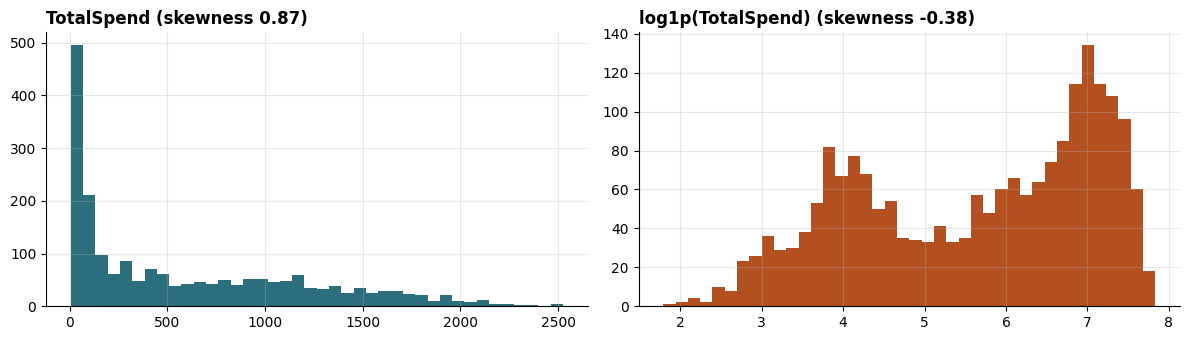

In [21]:
df["TotalSpend_log"] = np.log1p(df["TotalSpend"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.hist(df["TotalSpend"], bins=40, color=WARNA)
ax1.set_title(f"TotalSpend (skewness {df['TotalSpend'].skew():.2f})", loc="left", fontweight="bold")
ax2.hist(df["TotalSpend_log"], bins=40, color=WARNA_SOROT)
ax2.set_title(f"log1p(TotalSpend) (skewness {df['TotalSpend_log'].skew():.2f})", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Skewness** mengukur kemiringan sebaran: 0 berarti simetris, positif berarti ekor ke kanan, negatif berarti ekor ke kiri.

💬 **Amati:**

1. Apakah sebarannya menjadi lebih seimbang? Apakah transformasi log membuatnya simetris sempurna?
2. Setelah transformasi log, berapa "puncak" yang terlihat pada histogram? Apa yang mungkin ditunjukkan oleh beberapa puncak tentang pelanggan RetailKu? Simpan dugaanmu untuk Pertemuan 4.

### 4.6 Membungkus semuanya dalam satu fungsi

Semua langkah di atas kita satukan dalam fungsi `buat_fitur()`. Dengan begitu, data pelanggan baru bisa diproses dengan cara yang **persis sama**.

In [22]:
KOLOM_BELANJA = kolom_belanja
KOLOM_PEMBELIAN = kolom_pembelian
KOLOM_KAMPANYE_LALU = kolom_kampanye_lalu

def buat_fitur(data):
    data = data.copy()
    data["Age"] = TAHUN_ACUAN - data["Year_Birth"]
    data["Tenure_days"] = (TANGGAL_ACUAN - data["Dt_Customer"]).dt.days
    data["Children"] = data["Kidhome"] + data["Teenhome"]
    data["TotalSpend"] = data[KOLOM_BELANJA].sum(axis=1)
    data["TotalPurchases"] = data[KOLOM_PEMBELIAN].sum(axis=1)
    data["TotalAcceptedPrev"] = data[KOLOM_KAMPANYE_LALU].sum(axis=1)
    data["AvgSpendPerPurchase"] = data["TotalSpend"] / data["TotalPurchases"].replace(0, np.nan)
    data["AgeGroup"] = pd.cut(data["Age"], bins=[0, 30, 45, 60, 120], labels=["<=30", "31-45", "46-60", ">60"])
    data["TotalSpend_log"] = np.log1p(data["TotalSpend"])
    return data

df = buat_fitur(bersih)
print("Ukuran setelah feature engineering:", df.shape)

Ukuran setelah feature engineering: (2026, 36)


`IncomeGroup` sengaja tidak dimasukkan ke fungsi. Batas kuartilnya dihitung dari seluruh data, dan ini akan jadi masalah. Kenapa? Kita bahas di bagian 7.

---
## 5. Encoding: mengubah kategori menjadi angka

In [23]:
print(df["Education"].value_counts(), "\n")
print(df["Marital_Status"].value_counts())

Education
Graduation    1017
Master         518
PhD            442
Basic           49
Name: count, dtype: int64 

Marital_Status
Married     788
Together    512
Single      441
Divorced    215
Widow        70
Name: count, dtype: int64


### 5.1 Jebakan *label encoding*

Cara paling cepat adalah memberi nomor pada setiap kategori.

In [24]:
nomor_status = df["Marital_Status"].astype("category").cat.codes
pd.DataFrame({"Marital_Status": df["Marital_Status"], "nomor": nomor_status}).drop_duplicates().sort_values("nomor")

,Marital_Status,nomor
6,Divorced,0
4,Married,1
0,Single,2
2,Together,3
36,Widow,4


💬 **Diskusi:** bagi model, angka punya urutan dan jarak. Dengan nomor di atas, model akan "mengira" status dengan nomor 4 lebih besar daripada status dengan nomor 1, atau bahwa jarak antara dua status bisa dihitung. Masuk akalkah?

<details>
<summary><b>Penjelasan</b></summary>

Status pernikahan tidak punya urutan. Memberinya nomor 0–4 menciptakan urutan palsu yang bisa menyesatkan model. Label encoding hanya aman untuk kategori yang **memang berurutan**, atau untuk model tertentu yang tidak membaca urutan (dibahas di pertemuan berikutnya).

</details>

### 5.2 Ordinal encoding: kategori yang berurutan

Jenjang pendidikan **punya urutan**: Basic < Graduation < Master < PhD. Kita tentukan urutannya sendiri, tidak mengikuti abjad.

In [25]:
URUTAN_PENDIDIKAN = ["Basic", "Graduation", "Master", "PhD"]

df["Education_ord"] = df["Education"].map({nama: i for i, nama in enumerate(URUTAN_PENDIDIKAN)})
df[["Education", "Education_ord"]].drop_duplicates().sort_values("Education_ord")

,Education,Education_ord
10,Basic,0
0,Graduation,1
5,Master,2
4,PhD,3


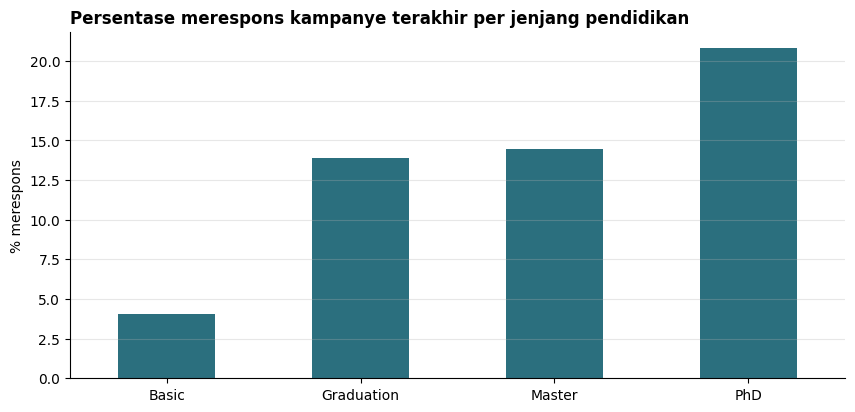

In [26]:
respons_pendidikan = df.groupby("Education")["Response"].mean().reindex(URUTAN_PENDIDIKAN) * 100

ax = respons_pendidikan.plot(kind="bar", color=WARNA, rot=0)
ax.set_title("Persentase merespons kampanye terakhir per jenjang pendidikan", loc="left", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("% merespons")
ax.grid(axis="x", visible=False)
plt.show()

### 5.3 One-hot encoding: kategori tanpa urutan

Untuk kategori tanpa urutan, setiap kategori dijadikan **kolom sendiri** berisi 1 (ya) atau 0 (tidak).

In [27]:
one_hot = pd.get_dummies(df["Marital_Status"], prefix="Status", dtype=int)
pd.concat([df["Marital_Status"], one_hot], axis=1).head()

,Marital_Status,Status_Divorced,Status_Married,Status_Single,Status_Together,Status_Widow
0,Single,0,0,1,0,0
1,Single,0,0,1,0,0
2,Together,0,0,0,1,0
3,Together,0,0,0,1,0
4,Married,0,1,0,0,0


💬 **Diskusi:**

1. Setiap baris pasti punya tepat satu angka 1. Jika keempat kolom lainnya 0, bisakah kita menebak isi kolom kelima? (Inilah alasan opsi `drop_first=True` kadang dipakai.)
2. Bagaimana jika sebuah kolom kategori punya 500 nilai berbeda, misalnya nama kota? Apa masalahnya bagi one-hot encoding?

---
## 6. Scaling: menyetarakan skala

### 6.1 Kenapa perlu?

Tiga pelanggan berikut. Siapa yang **paling mirip** dengan pelanggan A?

In [28]:
contoh = pd.DataFrame({
    "Income":   [50_000, 51_000, 60_000],
    "Children": [0, 3, 0],
}, index=["A", "B", "C"])
contoh

,Income,Children
A,50000,0
B,51000,3
C,60000,0


Secara akal sehat, C lebih mirip A: sama-sama tidak punya anak, pendapatannya beda 10 ribu. B punya tiga anak.

Banyak model mengukur kemiripan dengan **jarak** (Pertemuan 4 akan memakainya). Mari hitung jaraknya.

In [29]:
def jarak(data, p, q):
    return np.sqrt(((data.loc[p] - data.loc[q]) ** 2).sum())

print(f"Jarak A-B: {jarak(contoh, 'A', 'B'):,.1f}")
print(f"Jarak A-C: {jarak(contoh, 'A', 'C'):,.1f}")

Jarak A-B: 1,000.0
Jarak A-C: 10,000.0


💬 **Amati:** menurut perhitungan ini, siapa yang paling mirip dengan A? Kenapa perbedaan tiga anak hampir tidak berpengaruh?

Karena satuan `Income` jauh lebih besar, kolom itu mendominasi jarak. Solusinya: ubah semua kolom ke skala yang setara. Kita ubah memakai rata-rata dan simpangan baku dari **seluruh data pelanggan**.

In [30]:
rata2 = df[["Income", "Children"]].mean()
sd = df[["Income", "Children"]].std()

contoh_skala = (contoh - rata2) / sd
print(contoh_skala.round(2), "\n")
print(f"Jarak A-B setelah disetarakan: {jarak(contoh_skala, 'A', 'B'):.2f}")
print(f"Jarak A-C setelah disetarakan: {jarak(contoh_skala, 'A', 'C'):.2f}")

   Income  Children
A   -0.09     -1.28
B   -0.05      2.74
C    0.37     -1.28 

Jarak A-B setelah disetarakan: 4.02
Jarak A-C setelah disetarakan: 0.46


### 6.2 Dua cara yang paling umum

| Metode | Rumus | Hasil |
|---|---|---|
| **Standardization** (`StandardScaler`) | (x − rata-rata) / simpangan baku | Rata-rata 0, simpangan baku 1 |
| **Min-max scaling** (`MinMaxScaler`) | (x − min) / (max − min) | Semua nilai di antara 0 dan 1 |

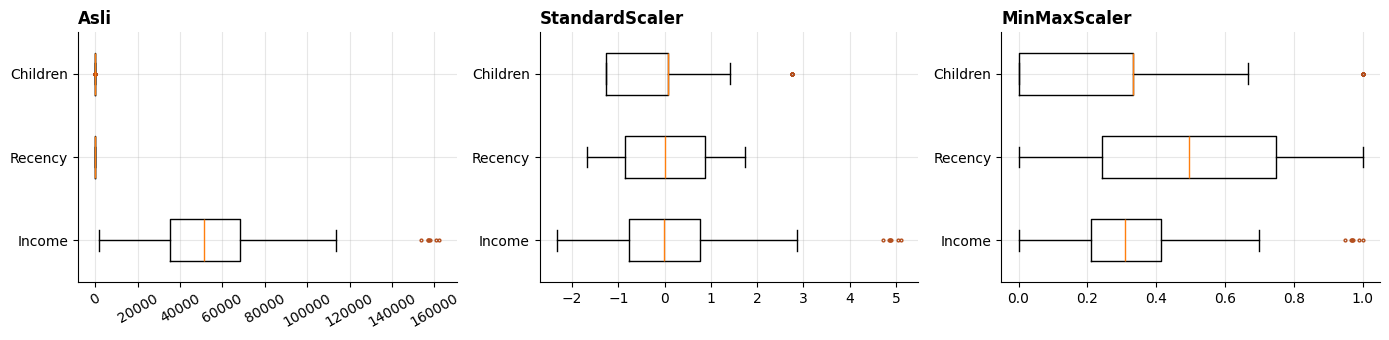

In [31]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

kolom_contoh = ["Income", "Recency", "Children"]
asli = df[kolom_contoh].dropna()

standar = pd.DataFrame(StandardScaler().fit_transform(asli), columns=kolom_contoh)
minmax = pd.DataFrame(MinMaxScaler().fit_transform(asli), columns=kolom_contoh)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (judul, data) in zip(axes, [("Asli", asli), ("StandardScaler", standar), ("MinMaxScaler", minmax)]):
    ax.boxplot([data[k] for k in kolom_contoh], vert=False, widths=0.5,
               flierprops={"markersize": 2, "markeredgecolor": WARNA_SOROT})
    ax.set_yticks(range(1, len(kolom_contoh) + 1))
    ax.set_yticklabels(kolom_contoh)
    ax.set_title(judul, loc="left", fontweight="bold")
axes[0].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

💬 **Amati:** pada panel "Asli", bisakah kamu melihat sebaran `Recency` dan `Children`? Bagaimana setelah di-scaling?

> Di bagian ini kita menghitung rata-rata, simpangan baku, min, dan max dari **seluruh data**, hanya untuk ilustrasi. Dalam praktik yang benar, cara itu termasuk **kebocoran data**. Bagian berikutnya menjelaskan kenapa.

---
## 7. Data latih, data uji, dan kebocoran data

### 7.1 Membagi data

Model dinilai dari kemampuannya menebak data yang **belum pernah ia lihat**. Seperti ujian: soal ujian tidak boleh sama dengan soal latihan. Karena itu data dibagi dua:

- **Data latih** (*train*), biasanya 70–80%, dipakai model untuk belajar.
- **Data uji** (*test*), sisanya, disimpan untuk menilai model di akhir.

Kita tentukan dulu fitur yang akan dipakai dan targetnya.

In [32]:
from sklearn.model_selection import train_test_split

FITUR_ANGKA = ["Income", "Age", "Tenure_days", "Recency", "Children", "TotalSpend_log",
               "TotalPurchases", "AvgSpendPerPurchase", "NumDealsPurchases",
               "NumWebVisitsMonth", "TotalAcceptedPrev", "Complain"]
FITUR_ORDINAL = ["Education"]
FITUR_NOMINAL = ["Marital_Status"]
TARGET = "Response"

X = df[FITUR_ANGKA + FITUR_ORDINAL + FITUR_NOMINAL]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print(f"% merespons di data latih: {y_train.mean() * 100:.1f}%")
print(f"% merespons di data uji  : {y_test.mean() * 100:.1f}%")

Data latih: (1620, 14) | Data uji: (406, 14)
% merespons di data latih: 15.3%
% merespons di data uji  : 15.3%


- `stratify=y` menjaga persentase pelanggan yang merespons **sama** di data latih dan data uji. Ini penting karena yang merespons hanya sebagian kecil pelanggan.
- `random_state=42` membuat pembagiannya sama setiap kali dijalankan, sehingga hasil kita dan hasil temanmu bisa dibandingkan.

### 7.2 Apa itu kebocoran data?

**Data leakage** terjadi ketika model, saat belajar, mendapat informasi yang **tidak akan tersedia saat dipakai sungguhan**. Hasil di notebook terlihat hebat, tetapi gagal di dunia nyata. Seperti siswa yang mendapat bocoran soal ujian: nilainya tinggi, padahal tidak paham.

**Bentuk 1: target ikut masuk ke fitur.** Ingat pertanyaan di bagian 4.2? Misalkan kita membuat fitur "jumlah semua kampanye yang diterima" **termasuk** kampanye terakhir.

In [33]:
fitur_bocor = df[KOLOM_KAMPANYE_LALU].sum(axis=1) + df["Response"]

pd.crosstab(fitur_bocor > 0, df["Response"],
            rownames=["pernah menerima kampanye (termasuk terakhir)"], colnames=["Response"])

Response,0,1
pernah menerima kampanye (termasuk terakhir),,
False,1464,0
True,252,310


💬 **Amati:** lihat baris `False`. Adakah pelanggan di baris itu yang merespons? Jadi, apa yang sebenarnya "diketahui" fitur ini? Dan kapan informasi itu tersedia: sebelum atau sesudah kampanye dikirim?

**Bentuk 2: data uji ikut "terlihat" saat menyiapkan data.** Median untuk mengisi nilai kosong, rata-rata dan simpangan baku untuk scaling, bahkan batas kuartil `IncomeGroup`: semuanya adalah hal yang **dipelajari** dari data. Jika dihitung dari seluruh data, informasi dari data uji ikut masuk ke proses belajar.

In [34]:
print(f"Median Income seluruh data: {df['Income'].median():,.1f}")
print(f"Median Income data latih  : {X_train['Income'].median():,.1f}")

Median Income seluruh data: 51,523.5
Median Income data latih  : 51,609.5


Bedanya kecil di sini, tetapi prinsipnya penting. Aturannya:

> Semua yang **dipelajari** dari data (median, rata-rata, simpangan baku, kategori, batas kuartil) hanya boleh dipelajari dari **data latih**. Data uji hanya **diubah** memakai hasil belajar itu.

Inilah alasan pengisian nilai kosong tidak lagi dilakukan di fungsi `bersihkan_data()`.

**Bentuk 3: data yang sama muncul di data latih dan data uji.** Ingat pelanggan yang tercatat dua kali di Pertemuan 2? Jika duplikat itu tidak dibuang, satu salinan bisa masuk data latih dan salinan lainnya masuk data uji. Model akan "menebak" data uji yang sebenarnya sudah ia hafal.

---
## 8. Pipeline: semua langkah dalam satu alur

Aturan di bagian 7 mudah dilanggar jika kita mengerjakan setiap langkah secara manual. `Pipeline` dan `ColumnTransformer` dari scikit-learn membantu:

- `fit` → **belajar** dari data latih (median, rata-rata, simpangan baku, daftar kategori).
- `transform` → **mengubah** data memakai hasil belajar itu.

Kita buat tiga jalur sesuai jenis kolom.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

jalur_angka = Pipeline([
    ("isi_kosong", SimpleImputer(strategy="median")),
    ("skala", StandardScaler()),
])

persiapan = ColumnTransformer([
    ("angka", jalur_angka, FITUR_ANGKA),
    ("ordinal", OrdinalEncoder(categories=[URUTAN_PENDIDIKAN],
                               handle_unknown="use_encoded_value", unknown_value=-1), FITUR_ORDINAL),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_NOMINAL),
], verbose_feature_names_out=False)

persiapan.set_output(transform="pandas")
persiapan

ColumnTransformer(transformers=[('angka',
                                 Pipeline(steps=[('isi_kosong',
                                                  SimpleImputer(strategy='median')),
                                                 ('skala', StandardScaler())]),
                                 ['Income', 'Age', 'Tenure_days', 'Recency',
                                  'Children', 'TotalSpend_log',
                                  'TotalPurchases', 'AvgSpendPerPurchase',
                                  'NumDealsPurchases', 'NumWebVisitsMonth',
                                  'TotalAcceptedPrev', 'Complain']),
                                ('ordinal',
                                 OrdinalEncoder(categories=[['Basic',
                                                             'Graduation',
                                                             'Master', 'PhD']],
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-1),
                                 ['Education']),
                                ('onehot',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Marital_Status'])],
                  verbose_feature_names_out=False)

Sekarang aturan emasnya: **fit hanya pada data latih**, lalu **transform** keduanya.

In [36]:
X_train_siap = persiapan.fit_transform(X_train)   # belajar + mengubah data latih
X_test_siap = persiapan.transform(X_test)         # hanya mengubah data uji

print("Data latih siap:", X_train_siap.shape)
print("Data uji siap  :", X_test_siap.shape)
X_train_siap.head()

Data latih siap: (1620, 18)
Data uji siap  : (406, 18)


,Income,Age,Tenure_days,Recency,Children,TotalSpend_log,TotalPurchases,AvgSpendPerPurchase,NumDealsPurchases,NumWebVisitsMonth,TotalAcceptedPrev,Complain,Education,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
150,-1.325866,-1.279559,-0.902599,1.461711,0.048360,-0.565579,-0.778552,-0.674369,0.853455,1.086797,-0.434486,-0.102981,1.0,0.0,1.0,0.0,0.0,0.0
1204,0.662179,-0.155341,0.648605,0.256987,0.048360,1.053020,0.753618,1.152594,0.853455,1.086797,1.056759,-0.102981,1.0,0.0,1.0,0.0,0.0,0.0
1093,1.439489,-0.414776,1.426685,-1.188683,-1.302374,1.296344,1.728635,1.215863,-0.705865,-1.391773,1.056759,-0.102981,1.0,0.0,0.0,0.0,1.0,0.0
1994,0.167879,-0.328297,-0.223638,0.497932,0.048360,0.465211,0.335753,-0.029577,-0.186092,0.260607,1.056759,-0.102981,1.0,0.0,0.0,0.0,1.0,0.0
1005,0.722270,-1.538995,0.485060,1.220766,-1.302374,0.836441,0.475041,0.720149,-0.705865,-1.804868,-0.434486,-0.102981,1.0,0.0,0.0,0.0,1.0,0.0


Apa yang dipelajari pipeline dari data latih?

In [37]:
imputer = persiapan.named_transformers_["angka"].named_steps["isi_kosong"]
scaler = persiapan.named_transformers_["angka"].named_steps["skala"]

pd.DataFrame({
    "median_untuk_mengisi": imputer.statistics_,
    "rata2_untuk_scaling": scaler.mean_,
    "sd_untuk_scaling": scaler.scale_,
}, index=FITUR_ANGKA).round(2)

,median_untuk_mengisi,rata2_untuk_scaling,sd_untuk_scaling
Income,51609.50,51955.56,21667.02
Age,43.50,44.80,11.56
Tenure_days,360.00,359.13,201.78
Recency,49.00,48.53,29.05
Children,1.00,0.96,0.74
TotalSpend_log,5.99,5.63,1.46
TotalPurchases,12.00,12.59,7.18
AvgSpendPerPurchase,29.85,37.28,29.64
NumDealsPurchases,2.00,2.36,1.92
NumWebVisitsMonth,6.00,5.37,2.42


In [38]:
ringkas = pd.DataFrame({
    "rata2_latih": X_train_siap[FITUR_ANGKA].mean(),
    "rata2_uji": X_test_siap[FITUR_ANGKA].mean(),
    "sd_latih": X_train_siap[FITUR_ANGKA].std(),
    "sd_uji": X_test_siap[FITUR_ANGKA].std(),
}).round(2)
ringkas

,rata2_latih,rata2_uji,sd_latih,sd_uji
Income,-0.0,0.02,1.0,0.98
Age,-0.0,0.13,1.0,1.03
Tenure_days,-0.0,-0.12,1.0,1.01
Recency,0.0,0.06,1.0,0.98
Children,-0.0,-0.08,1.0,1.04
TotalSpend_log,-0.0,-0.01,1.0,1.06
TotalPurchases,-0.0,-0.02,1.0,1.01
AvgSpendPerPurchase,-0.0,0.06,1.0,1.10
NumDealsPurchases,0.0,-0.06,1.0,1.03
NumWebVisitsMonth,0.0,-0.09,1.0,1.03


💬 **Amati:** pada data latih, rata-rata fitur angka tepat 0 dan simpangan bakunya 1. Kenapa pada data uji tidak tepat 0 dan 1? Apakah itu tanda ada yang salah?

<details>
<summary><b>Penjelasan</b></summary>

Tidak ada yang salah. Data uji diubah memakai rata-rata dan simpangan baku **data latih**, bukan miliknya sendiri. Justru begitulah seharusnya: data uji memperlakukan dirinya seperti data baru yang belum pernah dilihat.

</details>

### 8.1 Mencoba dengan pelanggan baru

Dua pelanggan baru mendaftar akhir Juni, setelah data latih kita disusun. Data mereka masih mentah: satu tidak mengisi pendapatan, satu lagi punya status pernikahan yang belum pernah muncul di data latih.

In [39]:
pelanggan_baru = pd.DataFrame([
    {"Year_Birth": 1985, "Education": "Master", "Marital_Status": "Married", "Income": 61000,
     "Kidhome": 1, "Teenhome": 0, "Dt_Customer": pd.Timestamp("2014-06-20"), "Recency": 5,
     "MntWines": 120, "MntFruits": 10, "MntMeatProducts": 80, "MntFishProducts": 15,
     "MntSweetProducts": 5, "MntGoldProds": 20, "NumDealsPurchases": 1, "NumWebPurchases": 2,
     "NumCatalogPurchases": 1, "NumStorePurchases": 3, "NumWebVisitsMonth": 6,
     "AcceptedCmp1": 0, "AcceptedCmp2": 0, "AcceptedCmp3": 0, "AcceptedCmp4": 0, "AcceptedCmp5": 0,
     "Complain": 0},
    {"Year_Birth": 1962, "Education": "PhD", "Marital_Status": "Engaged", "Income": np.nan,
     "Kidhome": 0, "Teenhome": 1, "Dt_Customer": pd.Timestamp("2014-06-25"), "Recency": 2,
     "MntWines": 600, "MntFruits": 40, "MntMeatProducts": 300, "MntFishProducts": 60,
     "MntSweetProducts": 30, "MntGoldProds": 50, "NumDealsPurchases": 2, "NumWebPurchases": 5,
     "NumCatalogPurchases": 4, "NumStorePurchases": 6, "NumWebVisitsMonth": 3,
     "AcceptedCmp1": 1, "AcceptedCmp2": 0, "AcceptedCmp3": 0, "AcceptedCmp4": 1, "AcceptedCmp5": 0,
     "Complain": 0},
])

fitur_baru = buat_fitur(pelanggan_baru)
persiapan.transform(fitur_baru[FITUR_ANGKA + FITUR_ORDINAL + FITUR_NOMINAL]).round(2)

,Income,Age,Tenure_days,Recency,Children,TotalSpend_log,TotalPurchases,AvgSpendPerPurchase,NumDealsPurchases,NumWebVisitsMonth,TotalAcceptedPrev,Complain,Education,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,0.42,-1.37,-1.73,-1.5,0.05,-0.07,-0.92,0.15,-0.71,0.26,-0.43,-0.1,2.0,0.0,1.0,0.0,0.0,0.0
1,-0.02,0.62,-1.75,-1.6,0.05,0.93,0.34,1.17,-0.19,-0.98,2.55,-0.1,3.0,0.0,0.0,0.0,0.0,0.0


💬 **Amati:**

1. Pendapatan pelanggan kedua kosong. Diisi dengan nilai berapa?
2. Status `Engaged` belum pernah muncul. Bagaimana kolom one-hot untuk pelanggan itu?
3. Angka-angka ini sudah di-scaling. Apa arti nilai `Tenure_days` yang negatif untuk kedua pelanggan ini? (Petunjuk: 0 berarti sama dengan rata-rata data latih.)
4. `TANGGAL_ACUAN` saat ini 1 Juli 2014. Apa yang perlu diubah jika fungsi ini dipakai untuk data tahun depan?

---
## 9. Menyimpan hasil

Kita simpan data bersih **beserta fitur barunya** (belum di-scaling). Pertemuan 4 dan 5 akan memakai file ini, lalu menyusun pipeline masing-masing di atasnya.

In [40]:
FILE_FITUR = "marketing_fitur.csv"
df.to_csv(FILE_FITUR, index=False)
print("Tersimpan:", FILE_FITUR, "| ukuran:", df.shape)

Tersimpan: marketing_fitur.csv | ukuran: (2026, 37)


In [41]:
# OPSIONAL: unduh file ke komputer (hapus tanda # di dua baris berikut)

# from google.colab import files
# files.download(FILE_FITUR)

---
## 10. Latihan mandiri

**Latihan 1 — Fitur preferensi.** Buat fitur `ShareWine` = `MntWines` / `TotalSpend`. Bandingkan rata-rata `ShareWine` antara pelanggan yang merespons dan yang tidak.
*Petunjuk:* `df.groupby("Response")["ShareWine"].mean()`

In [42]:
# Tulis jawaban Latihan 1 di sini

**Latihan 2 — Fitur keluarga.** Buat fitur `IsParent` (1 jika `Children` > 0, selain itu 0). Berapa persen orang tua yang merespons, dibanding yang bukan orang tua?

In [43]:
# Tulis jawaban Latihan 2 di sini

**Latihan 3 — Ganti scaler.** Salin definisi `jalur_angka` dan `persiapan`, ganti `StandardScaler()` dengan `MinMaxScaler()`, lalu fit ulang pada data latih. Berapa nilai minimum dan maksimum fitur angka di data latih? Bagaimana di data uji? Kenapa data uji bisa sedikit di luar 0–1?

In [44]:
# Tulis jawaban Latihan 3 di sini

**Latihan 4 — Detektif kebocoran.** Tim marketing mengusulkan lima fitur berikut untuk memprediksi `Response` kampanye ke-7. Mana yang aman dan mana yang bocor? Jelaskan alasannya.

| Usulan fitur | Aman / bocor? | Alasan |
|---|---|---|
| Jumlah kampanye 1–5 yang pernah diterima | | |
| Total belanja dalam 1 bulan **setelah** kampanye dikirim | | |
| Pendapatan pelanggan | | |
| Apakah pelanggan memakai kode promo kampanye tersebut | | |
| Median pendapatan yang dihitung dari seluruh data (latih + uji) | | |

**Latihan 5 (tantangan) — Log di dalam pipeline.** Daripada membuat kolom `TotalSpend_log` secara manual, tambahkan langkah `FunctionTransformer(np.log1p)` di dalam pipeline untuk kolom `TotalSpend`.
*Petunjuk:* buat jalur baru di `ColumnTransformer` khusus untuk `["TotalSpend"]` yang berisi `FunctionTransformer` lalu `StandardScaler`.

In [45]:
# Tulis jawaban Latihan 5 di sini

---
## 11. Tugas: kamus fitur untuk tim marketing

Tim marketing perlu memahami fitur yang kamu buat. Lengkapi **kamus fitur** berikut untuk minimal 6 fitur baru, dalam bahasa yang dimengerti orang non-teknis.

| Fitur | Cara menghitung | Arti bagi bisnis | Contoh pemakaian |
|---|---|---|---|
| `TotalSpend` | Jumlah 6 kolom belanja | Nilai belanja pelanggan selama 2 tahun | Mencari pelanggan bernilai tinggi |
| | | | |
| | | | |

Lalu tulis 3–4 kalimat untuk data scientist senior: bagaimana kamu memastikan tidak ada kebocoran data?

---
## Rangkuman

| Langkah | Masalah yang diatasi | Alat |
|---|---|---|
| Feature engineering | Informasi tersebar atau tersembunyi | Operasi kolom, `pd.cut`, `pd.qcut`, `np.log1p` |
| Encoding | Model hanya mengerti angka | Ordinal encoding (berurutan), one-hot encoding (tanpa urutan) |
| Scaling | Kolom berangka besar mendominasi | `StandardScaler`, `MinMaxScaler` |
| Split | Model harus diuji dengan data yang belum pernah dilihat | `train_test_split(..., stratify=y)` |
| Mencegah kebocoran | Hasil terlihat bagus padahal curang | Fit hanya di data latih |
| Pipeline | Langkah manual mudah salah dan sulit diulang | `Pipeline`, `ColumnTransformer` |

**Pertemuan berikutnya, Unsupervised Learning:** dengan fitur-fitur ini kita mengelompokkan pelanggan RetailKu menjadi beberapa segmen, tanpa memberi tahu model jawaban yang benar.